In [1]:
import sys
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))

import numpy as np, matplotlib.pyplot as plt
from data import get_splits
from mlp import MLP, train_mlp, eval_loss_acc
from metrics import Timer

d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]

In [2]:
sizes = [8, 16, 32, 64, 128, 256, 512]
seeds = [0, 1, 2]
resA = {}
for H in sizes:
    va, tr, ts = [], [], []
    for s in seeds:
        net = MLP(n_hidden=H, seed=s)
        with Timer() as t:
            train_mlp(net, Xtr, ytr, Xva, yva, lr=0.1, epochs=20, batch_size=128, seed=s, track=False)
        va.append(eval_loss_acc(net, Xva, yva)[1])
        tr.append(eval_loss_acc(net, Xtr, ytr)[1])
        ts.append(t.seconds)
    n_params = 784 * H + H + H * 10 + 10
    resA[H] = dict(va_mean=np.mean(va), va_std=np.std(va), tr_mean=np.mean(tr),
                   time=np.mean(ts), params=n_params)
    print(f"H={H:4d} | params {n_params:7d} | val {np.mean(va)*100:.2f} ± {np.std(va)*100:.2f}% | "
          f"train {np.mean(tr)*100:.2f}% | fit {np.mean(ts):.1f}s")

H=   8 | params    6370 | val 91.49 ± 0.50% | train 92.62% | fit 2.8s
H=  16 | params   12730 | val 94.43 ± 0.11% | train 95.74% | fit 2.7s
H=  32 | params   25450 | val 96.10 ± 0.23% | train 97.37% | fit 3.7s
H=  64 | params   50890 | val 96.82 ± 0.06% | train 98.27% | fit 6.1s
H= 128 | params  101770 | val 97.13 ± 0.09% | train 98.68% | fit 9.4s
H= 256 | params  203530 | val 97.39 ± 0.08% | train 98.92% | fit 337.5s
H= 512 | params  407050 | val 97.45 ± 0.06% | train 99.09% | fit 338.5s


In [3]:
lrs = [0.01, 0.03, 0.1, 0.3, 1.0]
resB = {}
for lr in lrs:
    net = MLP(n_hidden=128, seed=0)
    h = train_mlp(net, Xtr, ytr, Xva, yva, lr=lr, epochs=20, batch_size=128, seed=0)
    resB[lr] = h
    print(f"lr={lr}: val acc epoch 20 = {h['val_acc'][-1]*100:.2f}% | "
          f"train loss {h['train_loss'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f}")

lr=0.01: val acc epoch 20 = 93.11% | train loss 0.2260 | val loss 0.2459
lr=0.03: val acc epoch 20 = 95.77% | train loss 0.1302 | val loss 0.1552
lr=0.1: val acc epoch 20 = 97.19% | train loss 0.0534 | val loss 0.0996
lr=0.3: val acc epoch 20 = 97.69% | train loss 0.0120 | val loss 0.0855
lr=1.0: val acc epoch 20 = 97.64% | train loss 0.0030 | val loss 0.1068


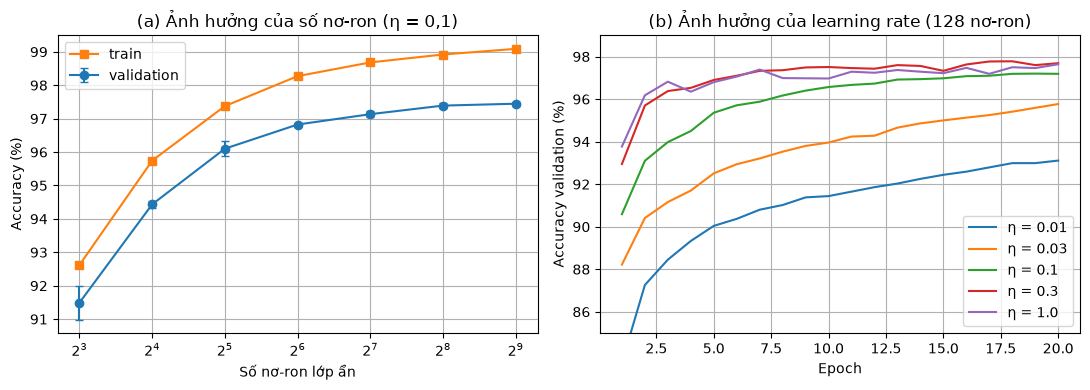

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# (a) số nơ-ron
Hs = list(resA)
ax[0].errorbar(Hs, [resA[h]["va_mean"] * 100 for h in Hs],
               yerr=[resA[h]["va_std"] * 100 for h in Hs], marker="o", capsize=3, label="validation")
ax[0].plot(Hs, [resA[h]["tr_mean"] * 100 for h in Hs], marker="s", label="train")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("Số nơ-ron lớp ẩn"); ax[0].set_ylabel("Accuracy (%)")
ax[0].set_title("(a) Ảnh hưởng của số nơ-ron (η = 0,1)"); ax[0].legend(); ax[0].grid(True)

# (b) learning rate, đường học theo epoch
for lr, h in resB.items():
    ax[1].plot(range(1, 21), np.array(h["val_acc"]) * 100, label=f"η = {lr}")
ax[1].set_ylim(85, 99)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy validation (%)")
ax[1].set_title("(b) Ảnh hưởng của learning rate (128 nơ-ron)"); ax[1].legend(); ax[1].grid(True)

plt.tight_layout()
plt.savefig(p / "report" / "mlp_hyper.png", dpi=150)
plt.show()

In [5]:
best_H = max(resA, key=lambda h: resA[h]["va_mean"])
best_lr = max(resB, key=lambda lr: resB[lr]["val_acc"][-1])
print("Số nơ-ron tốt nhất theo validation (trung bình 3 seed):", best_H,
      f"-> {resA[best_H]['va_mean']*100:.2f}%")
print("learning rate tốt nhất theo validation:", best_lr,
      f"-> {resB[best_lr]['val_acc'][-1]*100:.2f}%")

# các cấu hình nằm trong 1 độ lệch chuẩn của cấu hình tốt nhất
thr = resA[best_H]["va_mean"] - resA[best_H]["va_std"]
print("Cấu hình có số nơ-ron nằm trong 1 độ lệch chuẩn của tốt nhất:",
      [h for h in resA if resA[h]["va_mean"] >= thr])

Số nơ-ron tốt nhất theo validation (trung bình 3 seed): 512 -> 97.45%
learning rate tốt nhất theo validation: 0.3 -> 97.69%
Cấu hình có số nơ-ron nằm trong 1 độ lệch chuẩn của tốt nhất: [512]
